# Supervised anomaly detection with logistic regression

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

# Read data
using a url to a shared google drive

In [ ]:
url = "https://drive.google.com/uc?export=download&id=1Ev8LxlHvcdxndLWbk1ycbR90YjDfClfm"

# Load the CSV into a DataFrame directly from the URL
data = pd.read_csv(url)

# Display the first few rows to confirm
data


,Time (days),Ambient Temperature,Bearing Temperature,Label
0,0.000000,20.248357,30.579798,0.0
1,0.041696,21.225842,31.812579,0.0
2,0.083391,22.825420,32.915930,0.0
3,0.125087,24.298978,33.650562,0.0
4,0.166782,24.214868,34.414712,0.0
...,...,...,...,...
1435,59.833218,15.809345,25.354503,0.0
1436,59.874913,16.338191,25.869938,0.0
1437,59.916609,18.302097,27.968208,0.0
1438,59.958304,18.950514,29.096610,0.0


# Visualize the data

### on the time axis

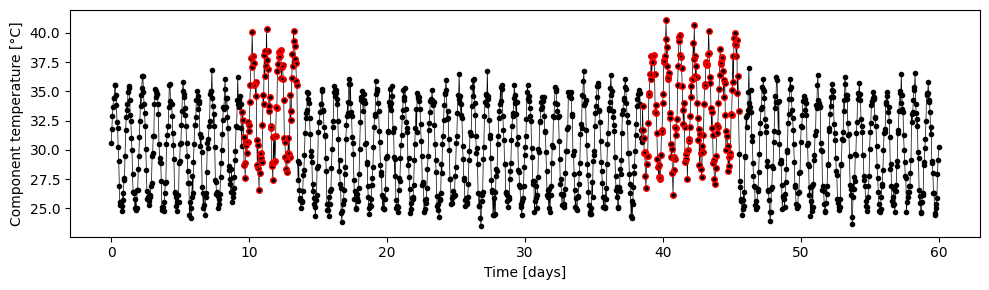

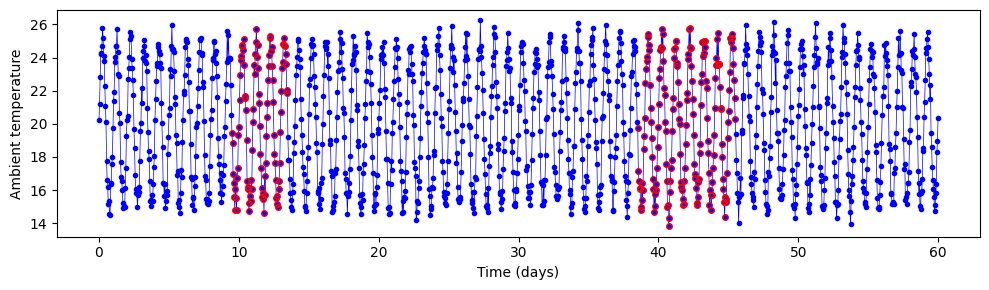

In [ ]:
# Highlight true anomalies in red
true_anomalies = data.loc[data['Label']==1]  # Use the indices of the true anomalies

# Bearing temperature
plt.figure(figsize=(10,3))
plt.plot(data['Time (days)'],data['Bearing Temperature'],'k-o',lw=0.5,ms=3)
plt.plot(true_anomalies['Time (days)'],true_anomalies['Bearing Temperature'],'ro',markerfacecolor='none',ms=4)

plt.xlabel('Time [days]')
plt.ylabel('Component temperature [°C]')
plt.tight_layout()
#plt.savefig('BearingTempCollective60Days.pdf')  # Save the figure
plt.show()

# Ambient temperature
plt.figure(figsize=(10,3))
plt.plot(data['Time (days)'],data['Ambient Temperature'],'b-o',lw=0.5,ms=3)
plt.plot(true_anomalies['Time (days)'],true_anomalies['Ambient Temperature'],'ro',markerfacecolor='none',ms=4)

plt.xlabel('Time (days)')
plt.ylabel('Ambient temperature')
plt.tight_layout()
plt.show()

# Download the figure
#files.download('BearingTempCollective60Days.pdf')

### pair plot

In [ ]:
import itertools

def pair_plot(df_data):
  # Create a pair plot
  num_vars = df_data.columns
  n = len(num_vars)

  fig, axes = plt.subplots(n, n, figsize=(5, 5))

  # Iterate through each subplot
  for i, j in itertools.product(range(n), range(n)):
      ax = axes[i, j]
      if i == j:
          # Diagonal: Plot histograms
          ax.hist(df_data[num_vars[i]], bins=50, color='lightblue', edgecolor='black')
          ax.set_title(num_vars[i])
      else:
          # Off-diagonal: Scatter plots
          ax.scatter(df_data[num_vars[j]], df_data[num_vars[i]], alpha=0.5, color='blue',s=2)

  # Adjust layout
  plt.tight_layout()
  plt.show()
  return fig,axes

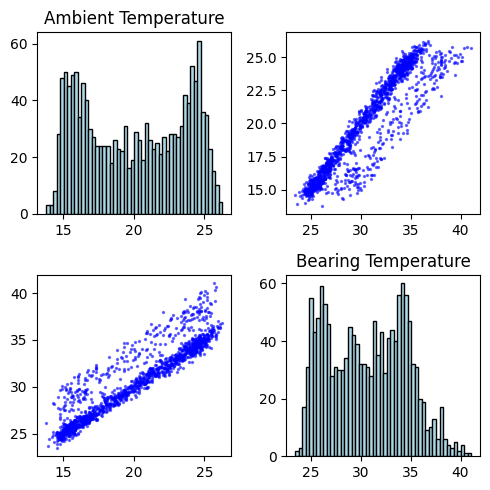

<Figure size 640x480 with 0 Axes>

In [ ]:
var_data = data[["Ambient Temperature","Bearing Temperature"]].copy()
fig,axes = pair_plot(var_data)

plt.tight_layout()
#fig.savefig('BearingTempAmbient_PairPlot.pdf')  # Save the figure

# Download the figure
#files.download('BearingTempAmbient_PairPlot.pdf')

# Classifying with logistic regression

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

## Train test split
We are assuming a supervised setting. This means that we have labeled training data. To train and then test a model we use the first N days for training (fault free days), and the rest for testing.

In [ ]:
# assume the first N days are labeled for training, the rest for testing
N = 30
# Define the split based on the first N days
train_data = data[data['Time (days)'] <= N]
test_data = data[data['Time (days)'] > N]

# Features (X) and target (y) for training and testing
X_train = train_data[['Ambient Temperature', 'Bearing Temperature']]
y_train = train_data['Label']  # Replace 'Label' with the name of your target column

X_test = test_data[['Ambient Temperature', 'Bearing Temperature']]
y_test = test_data['Label']


## Train logistic regression model and predict

In [ ]:
# Initialize the model
log_reg = LogisticRegression()

# Train the model on the first 30 days
log_reg.fit(X_train, y_train)

# Make predictions on the remaining data
y_pred = log_reg.predict(X_test)

# Make predictions on the training data
y_pred_train = log_reg.predict(X_train)



## Plot predictions

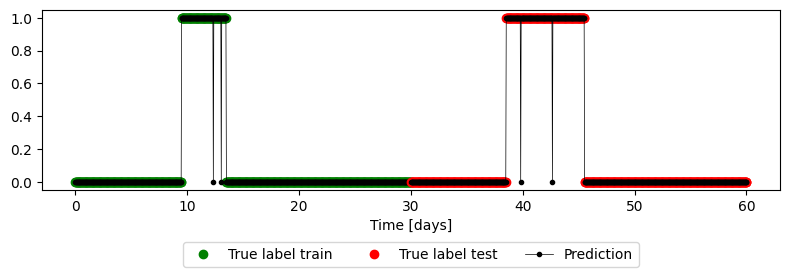

In [ ]:
plt.figure(figsize=(8,3))
plt.plot(train_data['Time (days)'],y_train,'go',label='True label train')
plt.plot(train_data['Time (days)'],y_pred_train,'k.-',lw=0.5)
plt.plot(test_data['Time (days)'],y_test,'ro',label='True label test')
plt.plot(test_data['Time (days)'],y_pred,'k.-',label='Prediction',lw=0.5)

plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.25), ncol=3)

plt.xlabel('Time [days]')
plt.tight_layout()
#plt.savefig('BearingTemp_LogRegPredictions.pdf')  # Save the figure
plt.show()

# Download the figure
#files.download('BearingTemp_LogRegPredictions.pdf')


## Think
1. To predict 0 or 1 there was an implicit assumption. what is it?
2. Can we improve the predictions if we drop this assumption?

## Refine the predictions using the probabilities
The logistic classifier sets the decision boundary at y_prob=0.5 by default. Is this always the right thing to do? Note that we are dealing with highly imbalanced data.

In [ ]:
# Training predictions: Get the predicted probabilities for the anomaly class (y=1)
y_prob_train = log_reg.predict_proba(X_train)[:, 1]  # Probability of the anomaly class

# Calculate the log-likelihood for each train point
log_likelihoods_train = y_train * np.log(y_prob_train) + (1 - y_train) * np.log(1 - y_prob_train)

# Testing predictions: Get the predicted probabilities for the anomaly class (y=1)
y_prob_test = log_reg.predict_proba(X_test)[:, 1]  # Probability of the anomaly class

# Calculate the log-likelihood for each test point
log_likelihoods_test = y_test * np.log(y_prob_test) + (1 - y_test) * np.log(1 - y_prob_test)



## Plot the predicted probabilities

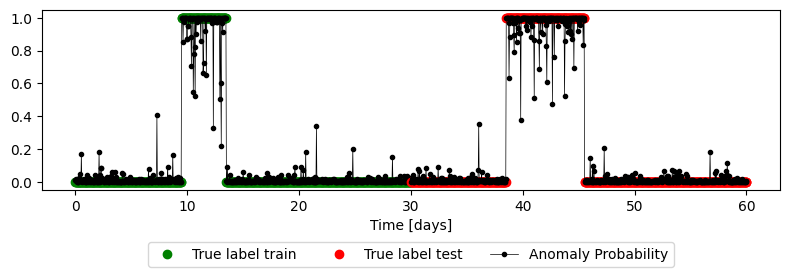

In [ ]:
plt.figure(figsize=(8,3))
plt.plot(train_data['Time (days)'],y_train,'go',label='True label train')
plt.plot(train_data['Time (days)'],y_prob_train,'k.-',lw=0.5)
plt.plot(test_data['Time (days)'],y_test,'ro',label='True label test')
plt.plot(test_data['Time (days)'],y_prob_test,'k.-',label='Anomaly Probability',lw=0.5)

plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.25), ncol=3)

plt.xlabel('Time [days]')
plt.tight_layout()
#plt.savefig('BearingTemp_LogRegProbabilities.pdf')  # Save the figure
plt.show()

# Download the figure
#files.download('BearingTemp_LogRegProbabilities.pdf')

# Evaluation: precision recall

## Define anomaly scores as prediction probabilities

In [ ]:
anomaly_scores = y_prob_test
true_labels = y_test

## Own precision-recall calculation

In [ ]:
def calculate_precision_recall_from_scratch(anomaly_scores, true_labels, threshold_array):
    """
    Calculate precision and recall for a given set of thresholds from scratch.

    Parameters:
    - anomaly_scores: Array-like, the anomaly scores output by the isolation forest.
                      Higher scores indicate a higher likelihood of being an anomaly.
    - true_labels: Array-like, ground truth labels (0 for normal, 1 for anomalies).
    - threshold_array: List or array of thresholds to evaluate.

    Returns:
    - precision: List of precision values for each threshold.
    - recall: List of recall values for each threshold.
    """
    precision = []
    recall = []

    for threshold in threshold_array:
        # Classify points as anomalies (1) or normal (0) based on the threshold
        predicted_labels = (anomaly_scores >= threshold).astype(int)

        # True Positives, False Positives, False Negatives
        tp = ((predicted_labels == 1) & (true_labels == 1)).sum()
        fp = ((predicted_labels == 1) & (true_labels == 0)).sum()
        fn = ((predicted_labels == 0) & (true_labels == 1)).sum()

        # Precision and Recall calculations
        prec = tp / (tp + fp) if (tp + fp) > 0 else 0
        rec = tp / (tp + fn) if (tp + fn) > 0 else 0

        precision.append(prec)
        recall.append(rec)

    return precision, recall



In [ ]:
threshold_arr = np.arange(0,1,0.01)
precision_test, recall_test = calculate_precision_recall_from_scratch(anomaly_scores, true_labels, threshold_arr)

## Precision-recall curve

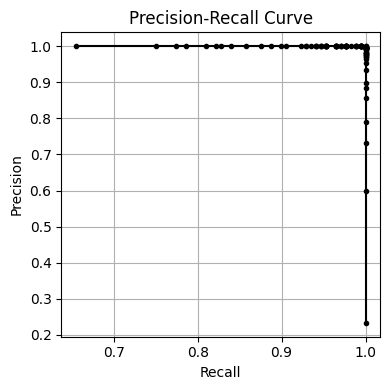

In [ ]:
plt.figure(figsize=(4, 4))
plt.plot(recall_test,precision_test,'ko-',ms=3)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.grid()

plt.tight_layout()
#plt.savefig('BearingTemp_LogRegPRC.pdf')  # Save the figure

# Download the figure
#files.download('BearingTemp_LogRegPRC.pdf')

# Select a detection threshold
In the supervised scenario we can use the labeled training data to tune the decision boundary.

In [ ]:
# use the labeled training data to set a desicion boundary
anomaly_scores_train = y_prob_train
true_labels_train = y_train

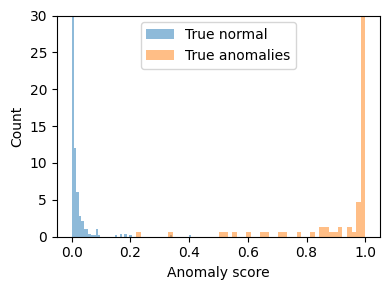

In [ ]:
# Plot the training scores to select a decision boundary
plt.figure(figsize=(4,3))
hist_train_0 = plt.hist(anomaly_scores_train[true_labels_train==0],50,alpha=0.5,density=True,label='True normal')
hist_train_1 = plt.hist(anomaly_scores_train[true_labels_train==1],50,alpha=0.5,density=True,label='True anomalies')
plt.ylim(0,30)
plt.xlabel('Anomaly score')
plt.ylabel('Count')
plt.legend(loc='upper center')
plt.tight_layout()

#plt.savefig('BearingTemp_LogRegAnomalyScoresHist.pdf')  # Save the figure
plt.show()
# Download the figure
#files.download('BearingTemp_LogRegAnomalyScoresHist.pdf')

## Think
1. Assuming labeled training data, how would you set a decision threshold? Hint: what is the tradeoff?
2. What decision criteria can you suggest?
3. Assume we want to minimize the missed detections, where would you set the threshold? (Recall = as many anomalies are detected out of the true anomalies)

## Select a decision criterion
Depending on the problem context, there are various decision criteria. Here, for example, we could assume that a failure is too risky to miss, whereas false alarms are tolerated. In other words we would like to minimize the false negatives. This corresponds to prioritizing a high recall over a high precision. The recall is defined as the fraction of correctly detected anomalied out of all true anomalies.  

In [ ]:
# calculate the recall on the training data
precision_train, recall_train = calculate_precision_recall_from_scratch(anomaly_scores_train, true_labels_train, threshold_arr)

In [ ]:
thresh_max_recall = np.max(threshold_arr[np.array(recall_train) == 1.0])
thresh_max_recall

np.float64(0.22)

In [ ]:
np.array(precision_train)[np.array(threshold_arr)==thresh_max_recall][0]

np.float64(0.9795918367346939)

## Precision and recall vs. threshold for the training data

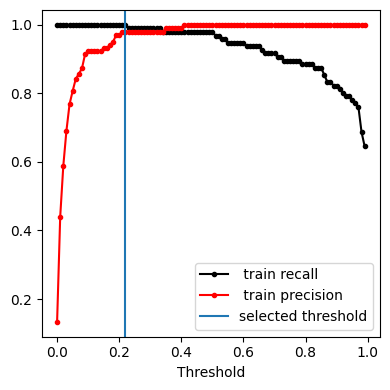

In [ ]:
plt.figure(figsize=(4,4))
plt.plot(threshold_arr,recall_train,'.-k',label=' train recall')
plt.plot(threshold_arr,precision_train,'.-r',label=' train precision')
plt.axvline(thresh_max_recall,label='selected threshold')
plt.xlabel('Threshold')
plt.legend(loc='lower right')
plt.tight_layout()
#plt.savefig('BearingTemp_LogRegPRCTraining.pdf')  # Save the figure
plt.show()

# Download the figure
#files.download('BearingTemp_LogRegPRCTraining.pdf')

## Presicion and recall vs. threshold for the test data

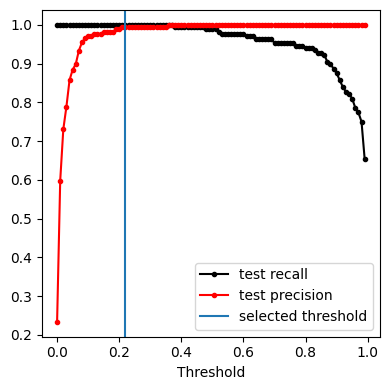

In [ ]:
plt.figure(figsize=(4,4))
plt.plot(threshold_arr,recall_test,'.-k',label='test recall')
plt.plot(threshold_arr,precision_test,'.-r',label='test precision')
plt.axvline(thresh_max_recall,label='selected threshold')
plt.xlabel('Threshold')
plt.legend(loc='lower right')
plt.tight_layout()
#plt.savefig('BearingTemp_LogRegPRCTest.pdf')  # Save the figure
plt.show()

# Download the figure
#files.download('BearingTemp_LogRegPRCTest.pdf')

## Plot as function of time

In [ ]:
detection_mask_test = y_prob_test > thresh_max_recall*1.2
detection_mask_train = y_prob_train > thresh_max_recall*1.2

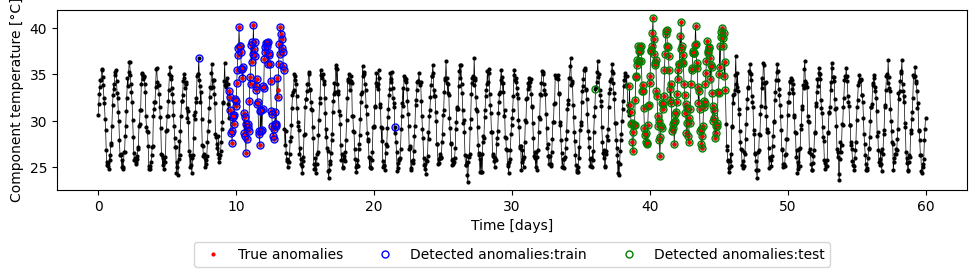

In [ ]:
# Highlight true anomalies with large empty yellow squares
true_anomalies = data.loc[data['Label']==1]  # Use the indices of the true anomalies
detected_anomalies_test = test_data.loc[detection_mask_test]
detected_anomalies_train = train_data.loc[detection_mask_train]


plt.figure(figsize=(10,3))
plt.plot(data['Time (days)'],data['Bearing Temperature'],'k-o',lw=0.5,ms=2)
plt.plot(true_anomalies['Time (days)'],true_anomalies['Bearing Temperature'],'ro',ms=2,label='True anomalies')
plt.plot(detected_anomalies_train['Time (days)'],detected_anomalies_train['Bearing Temperature'],'bo',markerfacecolor='none',ms=5,label='Detected anomalies:train')
plt.plot(detected_anomalies_test['Time (days)'],detected_anomalies_test['Bearing Temperature'],'go',markerfacecolor='none',ms=5,label='Detected anomalies:test')

plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.25), ncol=3)

plt.xlabel('Time [days]')
plt.ylabel('Component temperature [°C]')
#plt.xlim(7,15)
plt.tight_layout()
#plt.savefig('BearingTemp_LogRegDetection_partial.pdf')  # Save the figure
plt.show()

# Download the figure
#files.download('BearingTemp_LogRegDetection_partial.pdf')


## Think
1. can you find another way to improve the performance? Hint: think of continuity in time.
